# Vinculum 02 · Valuation ratios and the market through time

`fundamentals()` returns four valuation ratios ready-made (`vinculum.RATIOS`) next to any of the
31 EDGAR items, all point in time: each month-end row uses only filings available that day, and
that day's market cap. This notebook stays within vinculum (plus EDGAR's company profiles for an
industry); the full signal library, with thirty-odd ratios, growth, price and short-interest
signals, is `neural-processor` (see its notebooks).

1. built-in ratios
2. a market-wide panel, and ratios of your own
3. well-known companies side by side
4. cross-sectional distributions
5. industries, from SIC codes in EDGAR's profiles
6. through time: the market's valuation and profitability since 2012
7. one company, daily
8. caveats

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from edgar_cortical_node import EdgarStore
from subspace_probe import style, timed
from vinculum import RATIOS, Vinculum

style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_cols(16)
pl.Config.set_fmt_str_lengths(70)
v = Vinculum()
edgar = EdgarStore()
ITEMS = ["net_income", "equity", "revenue", "operating_cash_flow", "gross_profit", "operating_income",
         "assets", "liabilities", "long_term_debt", "dividends_paid"]
with timed(f"{len(ITEMS)} items and the built-in ratios, month ends 2012-2026"):
    f = v.fundamentals(ITEMS, start="2012-01-01")
# The largest companies each month: primary class, ranked by issuer market cap within the panel.
f = f.with_columns(pl.col("issuer_market_cap").rank("ordinal", descending=True).over("date").alias("size_rank"))
print(f"{f.height:,} rows, {f['cik'].n_unique():,} companies, {f['date'].n_unique()} month ends")

10 items and the built-in ratios, month ends 2012-2026: 1.11 s
926,512 rows, 11,116 companies, 179 month ends


## 1 · Built-in ratios

Each is a TTM flow or the latest balance sheet over **issuer market cap** (the whole company,
every share class), computed only for USD reporters:

In [2]:
pl.DataFrame({"ratio": list(RATIOS), "numerator": list(RATIOS.values()),
              "meaning": ["inverse P/E", "inverse P/B", "inverse P/S", "inverse P/CF"]})

ratio,numerator,meaning
str,str,str
"""earnings_yield""","""net_income""","""inverse P/E"""
"""book_to_market""","""equity""","""inverse P/B"""
"""sales_to_price""","""revenue""","""inverse P/S"""
"""cash_flow_yield""","""operating_cash_flow""","""inverse P/CF"""


In [3]:
f.filter(pl.col("ticker") == "AAPL").select("date", "ticker", "currency", "issuer_market_cap", *RATIOS).tail(4)

date,ticker,currency,issuer_market_cap,earnings_yield,book_to_market,sales_to_price,cash_flow_yield
date,str,str,f64,f64,f64,f64,f64
2026-08-31,"""AAPL""","""USD""",4.6288e12,0.027854,0.023228,0.100851,0.031698
2026-09-30,"""AAPL""","""USD""",4.8651e12,0.026501,0.0221,0.095954,0.030159
2026-10-30,"""AAPL""","""USD""",5.0347e12,0.025608,0.021356,0.092721,0.029143
2026-11-03,"""AAPL""","""USD""",4.8487e12,0.026591,0.022175,0.096278,0.03026


## 2 · Ratios of your own

Any other ratio is one polars expression over the same panel. Two rules keep them honest:
within-company ratios (margins, returns, leverage) use one filing's currency and work for every
company, while anything over market cap needs a USD reporter (there is no FX here); and a
denominator must be positive, so ROE on negative equity or a margin on zero revenue is missing,
not a misleading sign flip.

In [4]:
def ratio(num: str, den: str, usd_only: bool = False) -> pl.Expr:
    ok = pl.col(den) > 0
    if usd_only:
        ok = ok & (pl.col("currency") == "USD")
    return pl.when(ok).then(pl.col(num) / pl.col(den))


f = f.with_columns(
    ratio("gross_profit", "revenue").alias("gross_margin"),
    ratio("operating_income", "revenue").alias("operating_margin"),
    ratio("net_income", "revenue").alias("net_margin"),
    ratio("net_income", "equity").alias("roe"),
    ratio("gross_profit", "assets").alias("gross_profitability"),
    ratio("liabilities", "assets").alias("liabilities_to_assets"),
    ratio("long_term_debt", "equity").alias("debt_to_equity"),
    ratio("dividends_paid", "issuer_market_cap", usd_only=True).alias("dividend_yield"),
    pl.when(pl.col("earnings_yield") > 0).then(1 / pl.col("earnings_yield")).alias("pe"),
)
SHOW = [*RATIOS, "dividend_yield", "gross_margin", "operating_margin", "net_margin", "roe",
        "gross_profitability", "liabilities_to_assets", "debt_to_equity"]
f.filter(pl.col("ticker") == "AAPL").select("date", "pe", *SHOW).tail(3)

date,pe,earnings_yield,book_to_market,sales_to_price,cash_flow_yield,dividend_yield,gross_margin,operating_margin,net_margin,roe,gross_profitability,liabilities_to_assets,debt_to_equity
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-09-30,37.73425,0.026501,0.0221,0.095954,0.030159,0.003215,0.486529,0.33173,0.276186,1.199126,0.592599,0.719464,0.765439
2026-10-30,39.049771,0.025608,0.021356,0.092721,0.029143,0.003106,0.486529,0.33173,0.276186,1.199126,0.592599,0.719464,0.765439
2026-11-03,37.607344,0.026591,0.022175,0.096278,0.03026,0.003226,0.486529,0.33173,0.276186,1.199126,0.592599,0.719464,0.765439


## 3 · Well-known companies side by side

The latest month end. Reading down a column is a quick health check of the data: Apple's gross
margin near half of revenue, Nvidia's operating margin above 60%, Coca-Cola paying out most of
its earnings, JPMorgan with no gross or operating margin (banks have no such lines). Gaps follow
the items' coverage (`01_fundamentals.ipynb`): no total liabilities for some companies, no
dividends for those that pay none.

In [5]:
last = f["date"].max()
names = ["AAPL", "MSFT", "NVDA", "AMZN", "TSLA", "JPM", "KO", "WMT", "CVX", "PFE"]
snap = f.filter((pl.col("date") == last) & pl.col("ticker").is_in(names))
table = snap.to_pandas().set_index("ticker").loc[[n for n in names if n in snap["ticker"]], ["pe", *SHOW]].T
print(f"as known on {last}")
table.round(3)

as known on 2026-11-03


ticker,AAPL,MSFT,NVDA,AMZN,TSLA,JPM,KO,WMT,CVX,PFE
pe,37.607,27.129,25.826,20.113,489.489,13.808,27.885,44.873,21.615,39.471
earnings_yield,0.027,0.037,0.039,0.050,0.002,0.072,0.036,0.022,0.046,0.025
book_to_market,0.022,0.122,0.046,0.226,0.057,0.417,0.092,0.099,0.427,0.498
sales_to_price,0.096,0.090,0.061,0.294,0.066,0.222,0.125,0.743,0.484,0.373
cash_flow_yield,0.030,0.051,0.027,0.062,0.012,-0.181,0.040,0.043,0.102,0.078
dividend_yield,0.003,0.007,0.001,NaN,NaN,0.019,0.028,0.008,0.031,0.057
gross_margin,0.487,0.677,0.747,NaN,0.193,NaN,0.623,NaN,NaN,NaN
operating_margin,0.332,0.471,0.652,0.131,0.033,NaN,0.300,0.044,NaN,NaN
net_margin,0.276,0.412,0.637,0.169,0.031,0.326,0.287,0.030,0.096,0.068
roe,1.199,0.303,0.842,0.220,0.036,0.174,0.391,0.225,0.108,0.051


## 4 · Cross-sectional distributions

The 1,000 largest companies on the latest month end, each ratio clipped to its 1st-99th
percentile for the plot. Ratios with a small denominator (ROE near zero equity) have long tails;
rank or winsorize them before using them as signals (neural-processor does that per date).

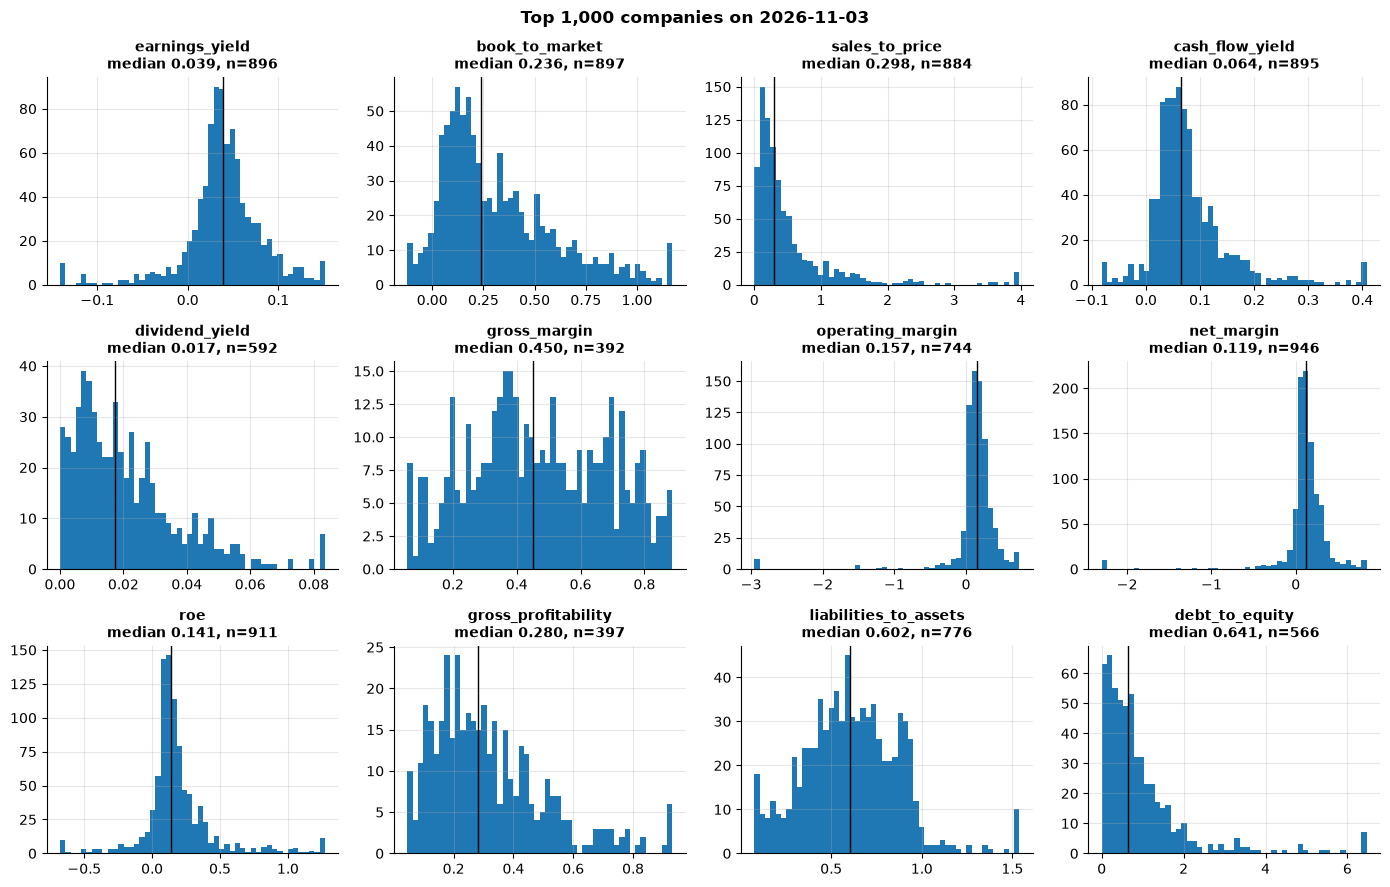

In [6]:
top = f.filter((pl.col("date") == last) & (pl.col("size_rank") <= 1000))
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, name in zip(axes.flat, SHOW, strict=True):
    s = top[name].drop_nulls()
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    ax.hist(s.clip(lo, hi), bins=50)
    ax.axvline(s.median(), color="black", lw=1)
    ax.set_title(f"{name}\nmedian {s.median():.3f}, n={s.len()}", fontsize=10)
fig.suptitle(f"Top 1,000 companies on {last}", fontweight="bold")
fig.tight_layout()
plt.show()

In [7]:
pl.DataFrame({"ratio": SHOW,
              "coverage": [top[n].is_not_null().mean() for n in SHOW],
              "negative": [(top[n] < 0).mean() for n in SHOW],
              "p01": [top[n].quantile(0.01) for n in SHOW],
              "median": [top[n].median() for n in SHOW],
              "p99": [top[n].quantile(0.99) for n in SHOW]}).with_columns(pl.col(pl.Float64).round(3))

ratio,coverage,negative,p01,median,p99
str,f64,f64,f64,f64,f64
"""earnings_yield""",0.896,0.1,-0.141,0.039,0.152
"""book_to_market""",0.897,0.056,-0.122,0.236,1.172
"""sales_to_price""",0.884,0.0,0.002,0.298,3.98
"""cash_flow_yield""",0.895,0.046,-0.082,0.064,0.408
"""dividend_yield""",0.592,0.002,0.0,0.017,0.084
"""gross_margin""",0.392,0.0,0.057,0.45,0.887
"""operating_margin""",0.744,0.094,-2.953,0.157,0.746
"""net_margin""",0.946,0.095,-2.301,0.119,0.842
"""roe""",0.911,0.093,-0.678,0.141,1.273


## 5 · Industries

Every row carries the company's CIK, so EDGAR's profiles supply an industry: the SIC division
(the first two digits of the SIC code), which needs no mapping table. SIC is today's code, not
point in time, which rarely matters for large companies. Medians across the top 1,000:

In [8]:
DIVISIONS = [(1, 9, "Agriculture"), (10, 14, "Mining, oil & gas"), (15, 17, "Construction"),
             (20, 39, "Manufacturing"), (40, 49, "Transport & utilities"), (50, 51, "Wholesale"),
             (52, 59, "Retail"), (60, 67, "Finance, insurance, real estate"), (70, 89, "Services")]


def division(sic: str | None) -> str | None:
    try:
        n = int(str(sic)[:2])
    except (TypeError, ValueError):
        return None
    return next((name for lo, hi, name in DIVISIONS if lo <= n <= hi), None)


prof = edgar.profiles(top["cik"].drop_nulls().unique().to_list()).select("cik", "sic", "sic_description")
prof = prof.with_columns(pl.col("sic").map_elements(division, return_dtype=pl.String).alias("division"))
top = top.join(prof, on="cik", how="left")
RATIO_COLS = ["gross_margin", "operating_margin", "roe", "earnings_yield", "book_to_market", "dividend_yield",
              "debt_to_equity", "liabilities_to_assets"]
by_div = (top.filter(pl.col("division").is_not_null()).group_by("division")
          .agg(pl.len().alias("companies"), pl.col("gross_margin").is_not_null().mean().alias("has_gross_margin"),
               *[pl.col(c).median() for c in RATIO_COLS])
          .sort("companies", descending=True).with_columns(pl.col(pl.Float64).round(3)))
by_div

division,companies,has_gross_margin,gross_margin,operating_margin,roe,earnings_yield,book_to_market,dividend_yield,debt_to_equity,liabilities_to_assets
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Manufacturing""",377,0.626,0.442,0.152,0.141,0.031,0.19,0.012,0.56,0.516
"""Finance, insurance, real estate""",204,0.069,0.61,0.214,0.118,0.057,0.494,0.025,0.653,0.811
"""Services""",173,0.416,0.726,0.152,0.175,0.03,0.136,0.012,0.664,0.598
"""Transport & utilities""",115,0.061,0.32,0.209,0.121,0.048,0.398,0.027,1.375,0.685
"""Retail""",50,0.52,0.342,0.087,0.316,0.047,0.129,0.021,0.678,0.732
"""Mining, oil & gas""",46,0.304,0.399,0.296,0.141,0.064,0.433,0.016,0.307,0.391
"""Wholesale""",20,0.85,0.24,0.043,0.152,0.04,0.225,0.008,0.651,0.683
"""Construction""",13,0.462,0.229,0.124,0.15,0.053,0.193,0.008,0.039,0.505
"""Agriculture""",1,0.0,null,null,0.04,0.127,3.174,0.061,null,null


The familiar patterns show up: finance carries the most liabilities per unit of assets (banks fund
themselves with deposits) and few financial companies report a gross margin at all, so that
median describes exchanges and payment companies rather than banks; manufacturing (which holds
most of technology and pharma under SIC) and services have the highest gross margins; utilities
and telecoms, inside transport and utilities, carry the most debt per unit of equity and pay the
highest dividends; retail runs on thin margins.

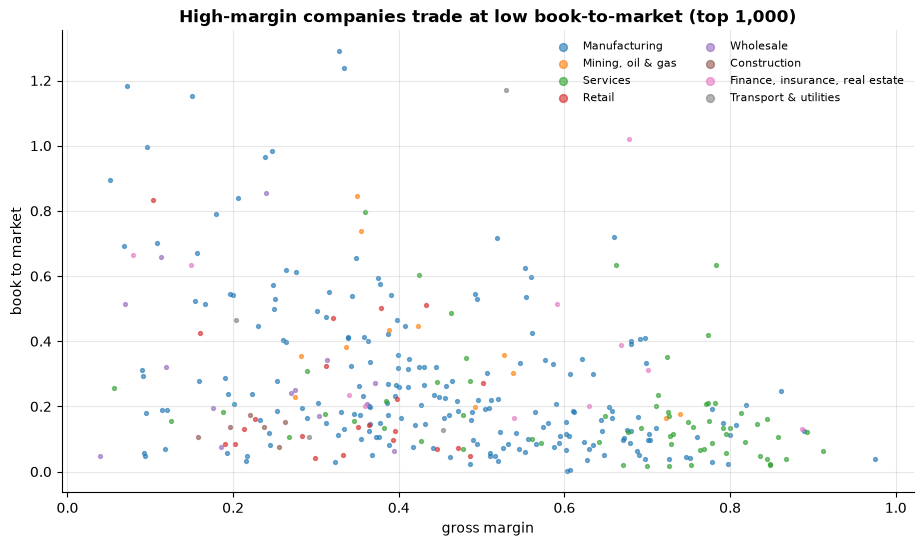

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
pts = top.filter(pl.col("division").is_not_null() & pl.col("gross_margin").is_between(-0.5, 1)
                 & pl.col("book_to_market").is_between(0, 3))
for (name,), g in pts.group_by("division", maintain_order=True):
    ax.scatter(g["gross_margin"], g["book_to_market"], s=8, alpha=0.6, label=name)
ax.set_xlabel("gross margin")
ax.set_ylabel("book to market")
ax.set_title("High-margin companies trade at low book-to-market (top 1,000)")
ax.legend(fontsize=8, ncol=2, markerscale=2)
plt.show()

## 6 · Through time

Medians across the 500 largest companies each month end (ranked by issuer market cap within
the panel), and the aggregate P/E (total market cap / total TTM net income of the same 500,
USD reporters), which is what an index P/E measures.

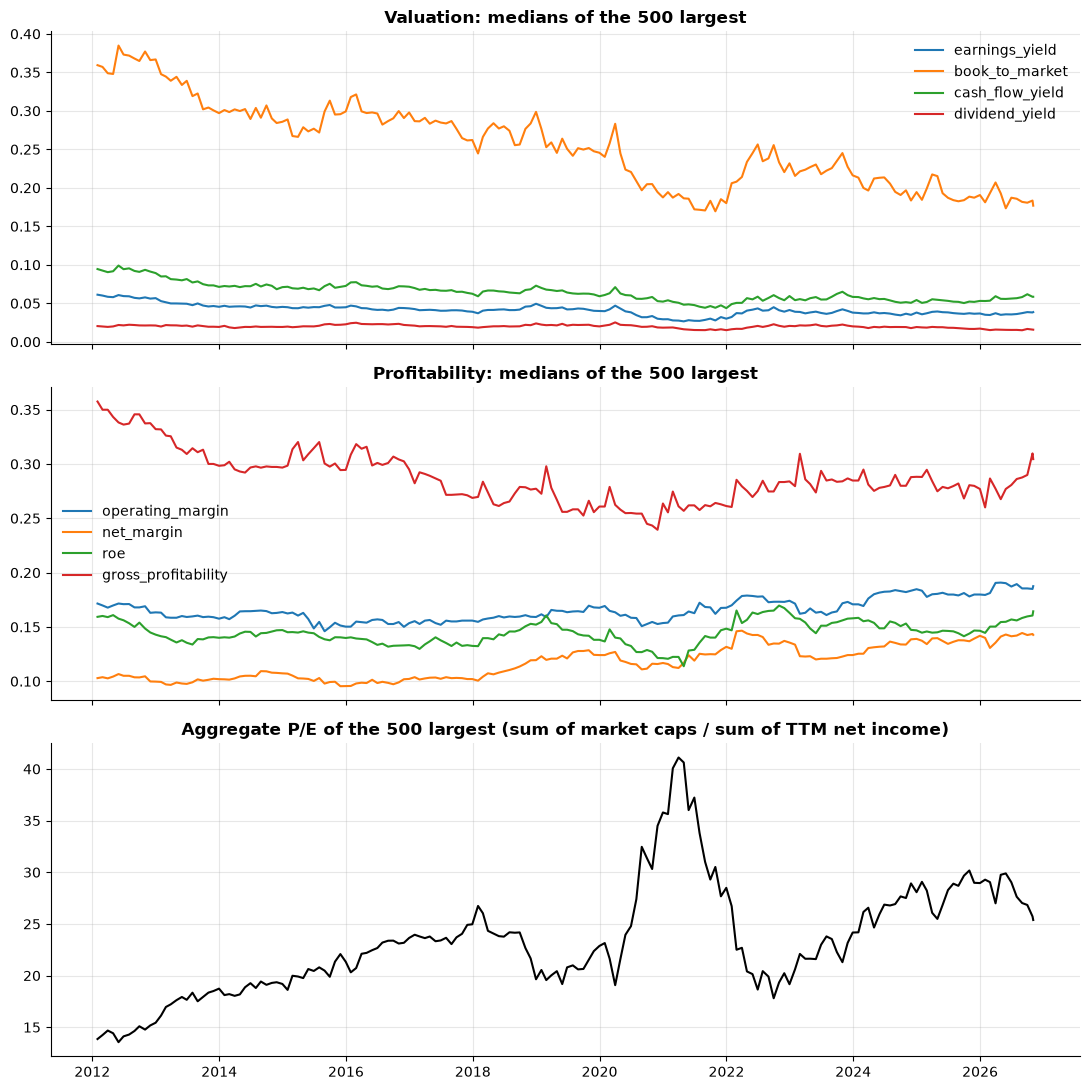

In [10]:
big = f.filter(pl.col("size_rank") <= 500)
med = big.group_by("date").agg(
    *[pl.col(c).median() for c in ["earnings_yield", "book_to_market", "cash_flow_yield", "dividend_yield",
                                   "operating_margin", "net_margin", "roe", "gross_profitability"]],
    (pl.col("issuer_market_cap").filter(pl.col("earnings_yield").is_not_null()).sum()
     / (pl.col("earnings_yield") * pl.col("issuer_market_cap")).sum()).alias("aggregate_pe")).sort("date")
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
for c in ["earnings_yield", "book_to_market", "cash_flow_yield", "dividend_yield"]:
    axes[0].plot(med["date"], med[c], label=c)
axes[0].set_title("Valuation: medians of the 500 largest")
axes[0].legend()
for c in ["operating_margin", "net_margin", "roe", "gross_profitability"]:
    axes[1].plot(med["date"], med[c], label=c)
axes[1].set_title("Profitability: medians of the 500 largest")
axes[1].legend()
axes[2].plot(med["date"], med["aggregate_pe"], color="black")
axes[2].set_title("Aggregate P/E of the 500 largest (sum of market caps / sum of TTM net income)")
fig.tight_layout()
plt.show()

In [11]:
med.filter(pl.col("date").dt.month() == 12).select(
    pl.col("date").dt.year().alias("year"), pl.col("aggregate_pe").round(1),
    (1 / pl.col("earnings_yield")).round(1).alias("median_pe"), pl.col("dividend_yield").round(4),
    pl.col("operating_margin").round(3))

year,aggregate_pe,median_pe,dividend_yield,operating_margin
i32,f64,f64,f64,f64
2012,15.4,17.6,0.0212,0.163
2013,18.7,22.0,0.0193,0.158
2014,19.2,22.0,0.0193,0.164
2015,21.3,22.3,0.0227,0.15
2016,23.6,23.1,0.0214,0.153
2017,25.0,25.6,0.019,0.156
2018,19.6,20.2,0.0239,0.159
2019,22.9,25.0,0.02,0.168
2020,35.8,34.2,0.0184,0.154


The aggregate P/E tracks the published S&P 500 trailing P/E: mid-teens in 2012, a spike at the
end of 2020 when pandemic earnings collapsed, back under 20 after the 2022 sell-off, higher again
by 2025. The median dividend yield is over companies that report dividends, so it reads higher
than an index yield.

## 7 · One company, daily

With `freq="1d"` every trading day gets a row: the price moves the ratio daily, and each filing
moves it in a step. Apple's P/E (1 / earnings yield) and the TTM net income behind it:

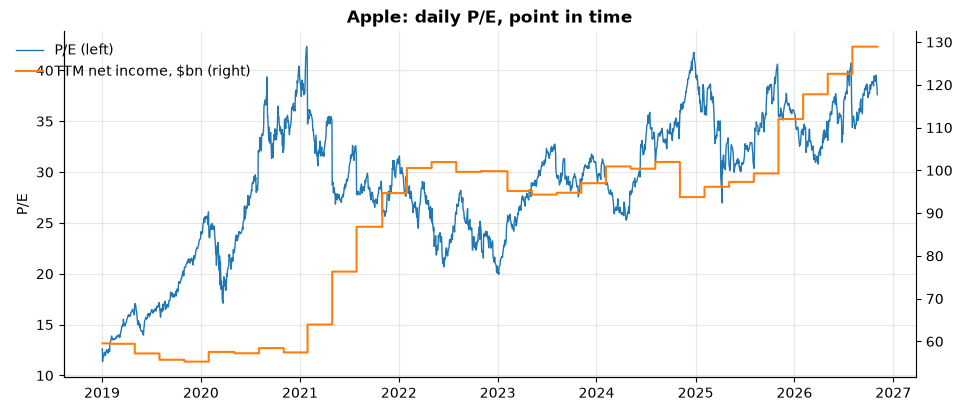

In [12]:
a = v.fundamentals(["net_income", "equity"], start="2019-01-01", tickers="AAPL", freq="1d")
fig, ax = plt.subplots()
ax.plot(a["date"], 1 / a["earnings_yield"], lw=1, label="P/E (left)")
ax.set_ylabel("P/E")
ax2 = ax.twinx()
ax2.step(a["date"], a["net_income"] / 1e9, where="post", color="tab:orange", label="TTM net income, $bn (right)")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Apple: daily P/E, point in time")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
plt.show()

## 8 · Caveats

- **Banks, insurers, REITs.** Revenue means different things (see 01), there is no gross profit
  or operating income for banks, and debt ratios are not comparable with industrial companies.
  Compare within an industry, or leave finance out of margin ratios.
- **USD reporters only** for anything over market cap; foreign filers' within-company ratios are
  fine, apart from the convenience-translation issue described in 01.
- **Multi-class companies** are valued through their primary class: `issuer_market_cap` covers
  all classes, so ratios are company-wide. Companies without a company-wide share count have no
  market cap and so no valuation ratios.
- **Point in time but not survivorship-filtered here**: the 500/1,000 largest are chosen each
  month from what existed then, so delisted companies are included while they traded.
- **Industry is today's SIC**, and divisions are coarse; neural-processor maps SIC codes to the
  Fama-French 12 industries for its sector-neutral transforms.